<h1><center>Module 2 : Stationnarité et Outils Mathématiques

In [40]:
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt

from statsmodels.tsa.stattools import adfuller
from scipy.stats import boxcox

In [41]:
# Définir un jeu de donnée fictif
np.random.seed(42)

n = 120
time = np.arange(n)
trend = 0.3 * (time** 1.4)
noise = np.random.normal(0, 1, n) * (time + 1) * 0.15
series = 20 + trend + noise

dates = pd.date_range(start= "2016-01-01", periods= n, freq= "ME")
df = pd.DataFrame({"Ventes": series}, index= dates)

df

,Ventes
2016-01-31,20.074507
2016-02-29,20.258521
2016-03-31,21.083165
2016-04-30,22.310479
2016-05-31,21.913706
...,...
2025-08-31,255.443167
2025-09-30,252.394306
2025-10-31,235.134847
2025-11-30,279.046434


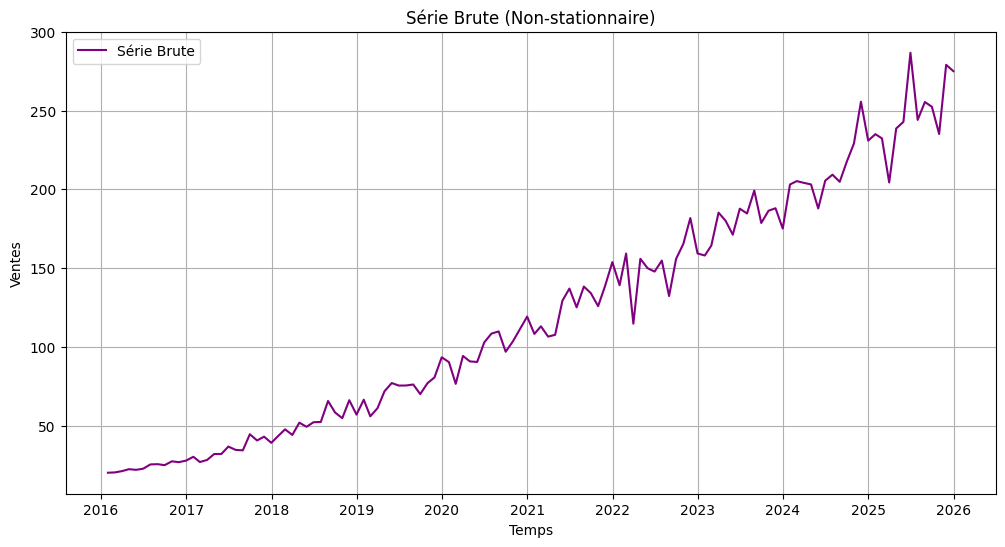

In [42]:
# visualization de la série

plt.figure(figsize=(12,6))
plt.plot(df.index, df['Ventes'], color="purple", label="Série Brute")
plt.title("Série Brute (Non-stationnaire)")
plt.xlabel("Temps")
plt.ylabel("Ventes")
plt.legend()
plt.grid(True)
plt.show()

In [43]:
moyenne = df['Ventes'].mean()
variance = df['Ventes'].var()


print(f"La moyenne de la série : {moyenne:.2f}")

print(f"La variance de la séries : {variance:.2f}")

# On ne peut pas savoir si la série est stationnaire.

La moyenne de la série : 120.44
La variance de la séries : 5534.52


### Test ADF

- Hypothèse nulle (H_0) : La série est non-stationnaire (elle possède une racine unitaire, c'est-à-dire une tendance).

- Hypothèse alternative (H_1) : La série est stationnaire.

- Règle de décision :On regarde la p-value. Si p-value < 0.05, on rejette l'hypothèse nulle (H_0).

- Conclusion : La série est stationnaire ! Si p-value > 0.05, on ne peut pas rejeter H_0, la série n'est donc pas stationnaire.

In [44]:
result_brut = adfuller(df['Ventes'])

print("Test ADF sur la série brute est : ")
print(result_brut, "\n")

print(f"p_value est : {result_brut[1]}")
# On a la p_value = 1 > 0.5 Donc on garde H0 --> La série n'est pas stationnaire


Test ADF sur la série brute est : 
(3.197376370370399, 1.0, 6, 113, {'1%': -3.489589552580676, '5%': -2.887477210140433, '10%': -2.580604145195395}, 802.2991004347575) 

p_value est : 1.0


### Pour rendre la série stationnaire, on va appliquer la transformation Box-Cox pour stabiliser la variance

In [45]:
series_boxcox, lmbda = boxcox(df["Ventes"])
print(f"lambda: {lmbda} \n {series_boxcox}")

lambda: 0.4039818757444614 
 [ 5.84003951  5.87074866  6.0063664   6.20247408  6.13979488  6.25476724
  6.66110502  6.68299037  6.59315488  6.94190866  6.86554462  7.00524014
  7.33142909  6.87841756  7.06231485  7.55660185  7.55962744  8.13374681
  7.8820876   7.84571416  8.99453944  8.57118829  8.83197368  8.40515109
  8.90284615  9.31167555  8.94736758  9.72472513  9.47284674  9.75267458
  9.76601058 10.94276653 10.31951687  9.99104033 10.98383979 10.19519777
 11.01039069 10.09977596 10.55913993 11.44223289 11.8398758  11.71777772
 11.72070736 11.76927751 11.29693952 11.83235578 12.10308566 12.99840765
 12.78756909 11.80078505 13.05314061 12.81971859 12.79615328 13.60917412
 13.95852683 14.04369202 13.22998663 13.65336381 14.1306186  14.6024109
 13.94668984 14.23870969 13.84064693 13.91266139 15.17005415 15.58889339
 14.93700893 15.65782856 15.43174981 14.97873772 15.68144534 16.45362983
 15.7015361  16.71956469 14.3387491  16.55786225 16.25868022 16.15104127
 16.5015061  15.3327552

### Ensuite, on applique la différenciation pour supprimer la tendance


In [46]:
series_diff = pd.Series(series_boxcox, index=df.index).diff().dropna()
series_diff

2016-02-29    0.030709
2016-03-31    0.135618
2016-04-30    0.196108
2016-05-31   -0.062679
2016-06-30    0.114972
                ...   
2025-08-31    0.423201
2025-09-30   -0.112434
2025-10-31   -0.652283
2025-11-30    1.609265
2025-12-31   -0.141040
Freq: ME, Length: 119, dtype: float64

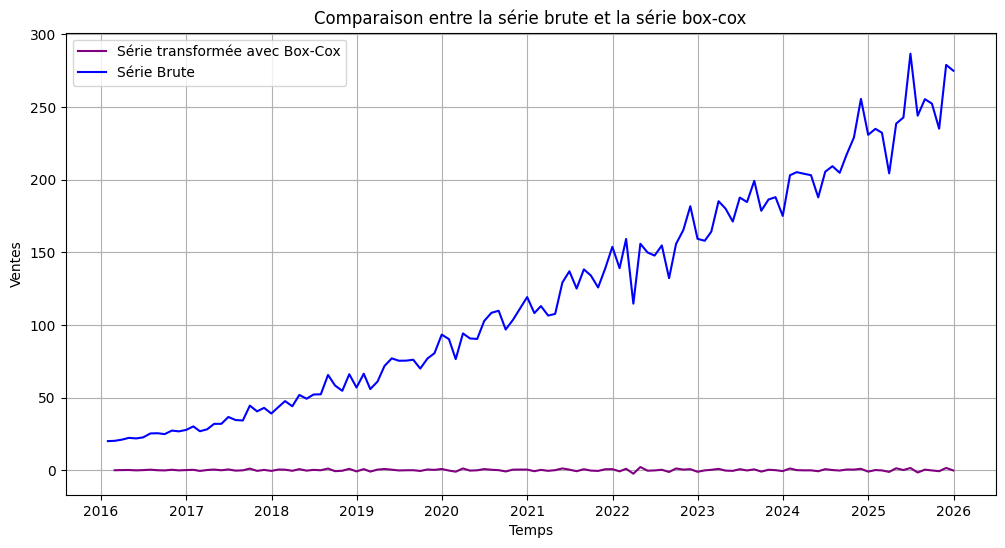

In [47]:

plt.figure(figsize=(12,6))
plt.plot(series_diff.index, series_diff, color="purple", label="Série transformée avec Box-Cox")
plt.plot(df.index, df['Ventes'], color="blue", label="Série Brute")

plt.title("Comparaison entre la série brute et la série box-cox")
plt.xlabel("Temps")
plt.ylabel("Ventes")
plt.legend()
plt.grid(True)
plt.show()

In [48]:
# On vérifie si la série est devenue stationnaire

result_brut = adfuller(series_diff)

print("Test ADF sur la série avec transformation BoxCox et différenciation est : ")
print(result_brut, "\n")

print(f"p_value est : {result_brut[1]}") 
# La p_value est inférieur à 0.5 donc on rejete H0 er la série est stationnaire

Test ADF sur la série avec transformation BoxCox et différenciation est : 
(-8.834821443075024, 1.730527460626849e-14, 5, 113, {'1%': -3.489589552580676, '5%': -2.887477210140433, '10%': -2.580604145195395}, 169.9168350159045) 

p_value est : 1.730527460626849e-14


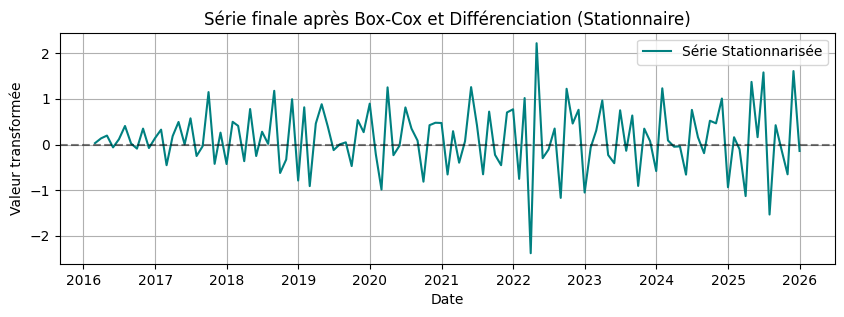

In [49]:
plt.figure(figsize=(10, 3))
plt.plot(series_diff.index, series_diff, color="teal", label="Série Stationnarisée")
plt.axhline(0, color="black", linestyle="--", alpha=0.5)
plt.title("Série finale après Box-Cox et Différenciation (Stationnaire)")
plt.xlabel("Date")
plt.ylabel("Valeur transformée")
plt.legend()
plt.grid(True)
plt.show()